In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

#### Testing loop with inherited demand

In [2]:
from app.services.security_class import arrivals_to_demand_grid
from app.services.coverage_dp import solve_coverage_batch_multi, allocate_milp, solve_allocated_multi, effective_grid, coverage_report_multi, fixed_window_solution, MultiAllocation   # MultiAllocation: lo stesso import già usato per allocate_milp

2026-11-20 18:16:19,291 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


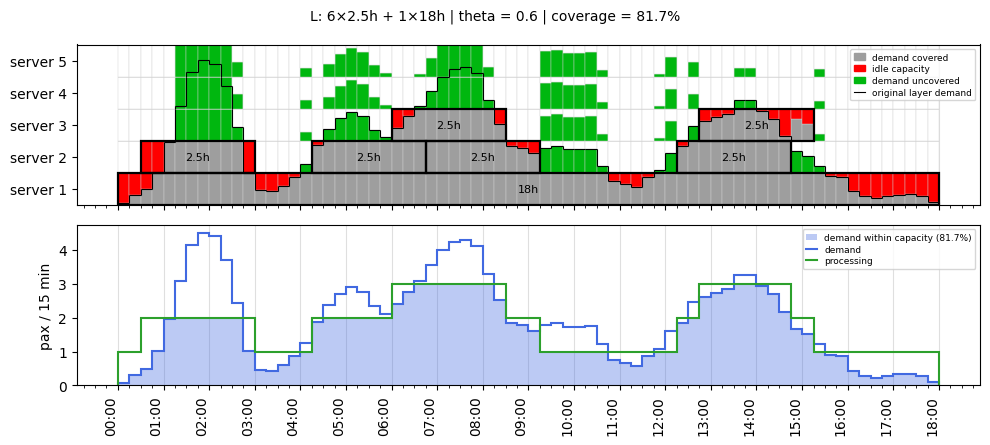

In [3]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, 15)
rates_in_order = [rate_by_label[l] for l in server_labels]

arrivals= samplers.expected_arrivals(flight_demand)
grid = arrivals_to_demand_grid(arrivals, utils.mean_processing_rate(server_registry))

lengths=[10]
theta=0.6
K_total= 20
length_totals={10:20}

# server sempre aperto 4:00-22:00 (riga 0)
bin_min    = 15
start_slot = 4  * 60 // bin_min
end_slot   = 22 * 60 // bin_min
T = grid.shape[1]
fixed = {0: fixed_window_solution(grid[0], theta, 0, T)}
n_fixed = len(fixed)

curves     = solve_coverage_batch_multi(grid[n_fixed:], lengths, theta)
alloc_free = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
alloc = MultiAllocation(
    k=np.vstack([np.zeros((n_fixed, len(lengths)), dtype=int), alloc_free.k]),
    lengths=alloc_free.lengths, value=alloc_free.value,
    per_row_value=np.concatenate([np.zeros(n_fixed), alloc_free.per_row_value]))

sols = solve_allocated_multi(grid, theta, alloc, inherit=True, fixed=fixed)

D_eff = effective_grid(grid, [s.coverage for s in sols])
time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = [str(r + 1) for r in range(grid.shape[0])]
blocks = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)]
          for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)
proc = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)

plotutils.plot_blocks(D=D_eff, D_ref=grid, blocks=blocks, labels=labels, time_values=time_values, theta=theta, bin_minutes=15,
                      demand_curve=rho, processing_curve=proc)

iter 0: objective=33.668 planned=15.014 coverage=0.8169 blocks=7 moved=0 d_eff_change=0.000  q_fluid=102.86


iter 1: objective=33.668 planned=15.739 coverage=0.8169 blocks=7 moved=0 d_eff_change=0.000  q_fluid=102.86
stop: fixed point
fixed point
 iter  objective  planned  coverage  n_blocks  capacity  moved  d_eff_change  q_fluid
    0     33.668   15.014     0.817         7     132.0      0           0.0  102.858
    1     33.668   15.739     0.817         7     132.0      0           0.0  102.858
blocchi 7 → 7 | capacità 132 → 132 | obiettivo 33.668 → 33.668 | coda fluida 102.9 → 102.9 min


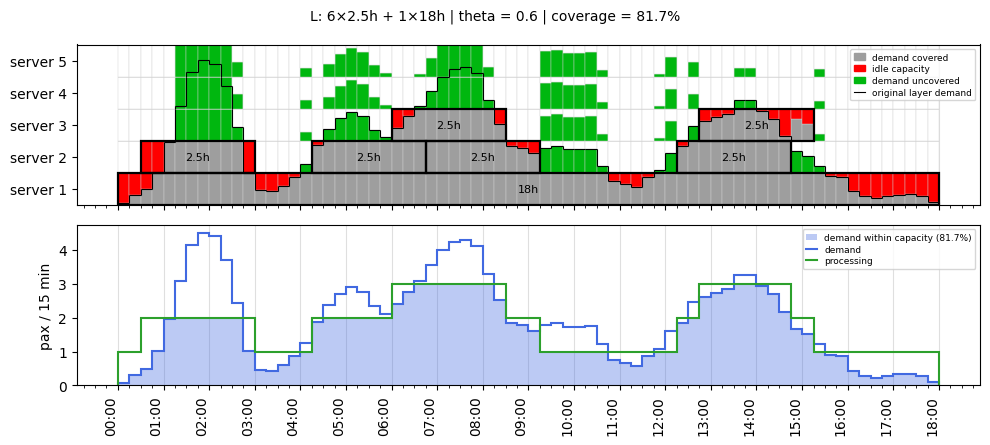

In [4]:
from app.services.inherited_loop import inherited_loop      # se l'hai già incollata nel notebook, salta questa riga

# baseline (pipeline normale) già calcolata sopra: sols
sols_A = sols

# loop: stesse impostazioni, stesso server fisso
sols_B, trace, history = inherited_loop(
    grid, lengths, theta, K_total, length_totals,
    n_iter=10, fixed=fixed, arrivals=arrivals, rates=rates_in_order, verbose=True)

print(trace.attrs["stop"])
print(trace.round(3).to_string(index=False))

# confronto A (iter 0) vs B (punto fisso)
a, b = trace.iloc[0], trace.iloc[-1]
print(f"blocchi {a.n_blocks:.0f} → {b.n_blocks:.0f} | capacità {a.capacity:.0f} → {b.capacity:.0f} | "
      f"obiettivo {a.objective:.3f} → {b.objective:.3f} | coda fluida {a.q_fluid:.1f} → {b.q_fluid:.1f} min")

# grafico della soluzione finale del loop
D_eff_B = effective_grid(grid, [s.coverage for s in sols_B])
blocks_B = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)] for r, sol in enumerate(sols_B)}
proc_B = np.sum([s.coverage[:grid.shape[1]] for s in sols_B], axis=0).astype(float)

plotutils.plot_blocks(D=D_eff_B, D_ref=grid, blocks=blocks_B, labels=labels, time_values=time_values,
                      theta=theta, bin_minutes=15, demand_curve=rho, processing_curve=proc_B)

In [8]:
import os
import numpy as np
import pandas as pd
from app.services.inherited_loop import loop_vs_theta_sweep, loop_verdict
from app.services.security_class import arrivals_to_demand_grid

# ===== parametri dell'esperimento =====
N_DAYS      = 100                        # i primi N giorni dello schedule
THETAS      = [0.2, 0.3, 0.4, 0.5]       # theta del loop
LS          = [2,3,4,5,6,7,8]                        # lunghezze L (slot), una per volta
LANE_BINS   = 1000                        # budget dei server liberi: K = LANE_BINS // L  (lane-bin = K * L)
FIXED_FIRST = "all"                      # None | "all" | (start_slot, lunghezza)
THETA_GRID  = np.round(np.arange(0, 1.0001, 0.025), 4)   # theta dello sweep di confronto
TOL_Q       = 5                          # min: soglia per i flag migliora/peggiora
BIN_MIN     = 15.0                       # ampiezza slot: inherited_loop usa 15 min nel fluido
# ======================================

def build_day_data(n_days):
    """{data: (arrivals (T,), demand grid (R, T))}, calcolato una volta sola. Giorni con errori vengono saltati."""
    schedule_std = preprocessing.preprocess_schedule_FLR(pd.read_excel(os.path.join("data", "schedule.xlsx")),
                                                         profile_specs={})
    arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
    registry = {i: dict(label=str(i), processing_rate=50, processing_unit=15, priority=5) for i in range(1, 7)}
    server_registry = preprocessing.build_processing_params_by_server(registry)
    mean_rate = utils.mean_processing_rate(server_registry)

    data = {}
    for d in sorted(schedule_std["date"].unique())[:n_days]:
        try:
            pred = predictive.predict_pax(df=schedule_std[schedule_std["date"] == d].copy(), path="data/pax_model.joblib")
            fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
            arr = np.asarray(samplers.expected_arrivals(fd), dtype=float)
            data[d] = (arr, arrivals_to_demand_grid(arr, mean_rate, BIN_MIN))
        except Exception as e:
            print(f"{d}: saltato ({e})")
    return data, server_registry

def run_loop_experiment(day_data, rates_in_order, Ls=LS, thetas=THETAS, lane_bins=LANE_BINS,
                        fixed_first=FIXED_FIRST, theta_grid=THETA_GRID, tol_q=TOL_Q, out_path=None):
    """
    Per ogni (L, giorno): loop_vs_theta_sweep. Se out_path e' dato (pkl), salva dopo ogni giorno e salta le coppie
    (day, L) gia' presenti: si puo' rilanciare dopo un'interruzione. Cambiando i parametri usa un altro out_path.
    """
    done = pd.read_pickle(out_path) if out_path and os.path.exists(out_path) else pd.DataFrame()
    frames = [done] if len(done) else []
    seen = set(zip(done["day"], done["L"])) if len(done) else set()

    for L in Ls:
        K = lane_bins // L
        if K == 0:
            raise ValueError(f"LANE_BINS={lane_bins} < L={L}: nessuna finestra allocabile")
        for d, (arr, grid) in day_data.items():
            day = pd.Timestamp(d).date()
            if (day, L) in seen:
                continue
            df_d = loop_vs_theta_sweep(grid, [L], thetas, K, {L: K}, arr, rates_in_order,
                                       theta_grid=theta_grid, tol_q=tol_q, fixed_first=fixed_first)
            df_d.insert(0, "day", day)
            df_d.insert(1, "L", L)
            frames.append(df_d)
            if out_path:
                pd.concat(frames, ignore_index=True).to_pickle(out_path)
        print(f"L={L}: {len(day_data)} giorni")
    return pd.concat(frames, ignore_index=True)

# --- esecuzione ---
day_data, server_registry = build_day_data(N_DAYS)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, BIN_MIN)
rates_in_order = [rate_by_label[l] for l in server_labels]

df_loop = run_loop_experiment(day_data, rates_in_order,
                              out_path=os.path.join("data", "loop_experiment.pkl"))

2026-11-20 18:17:26,251 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:26,694 | WARNING | app.services.preprocessing | More than 10% of flights (13/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:27,040 | WARNING | app.services.preprocessing | More than 10% of flights (8/58) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:28,265 | WARNING | app.services.preprocessing | More than 10% of flights (9/56) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:28,671 | WARNING | app.services.preprocessing | More than 10% of flights (9/61) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:28,948 | WARNING | app.services.preprocessing | More than 10% of flights (13/64) fall back to the unknown arrival sam

2026-05-22 00:00:00: saltato (Missing or invalid aircraft capacity for flights: ['BQ 2107'])


2026-11-20 18:17:38,177 | WARNING | app.services.preprocessing | More than 10% of flights (9/65) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:38,316 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:38,444 | WARNING | app.services.preprocessing | More than 10% of flights (8/61) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:38,544 | WARNING | app.services.preprocessing | More than 10% of flights (9/55) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:38,689 | WARNING | app.services.preprocessing | More than 10% of flights (10/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-20 18:17:38,787 | WARNING | app.services.preprocessing | More than 10% of flights (13/65) fall back to the unknown arrival sa

L=2: 93 giorni
L=3: 93 giorni
L=4: 93 giorni
L=5: 93 giorni
L=6: 93 giorni
L=7: 93 giorni
L=8: 93 giorni


In [17]:
df_loop

,day,L,theta,changed,same_as_theta,iters,stop,cap_A,cap_B,q_A,...,cov_B,obj_A,obj_B,q_front,advantage,overloaded,loop_beats_sweep,loop_worse_than_sweep,cap_match,cap_gap
0,2026-03-29,2,0.2,False,0.2,1,fixed point,164.0,164.0,0.134207,...,0.992807,100.375177,100.375177,0.134207,0.000000,False,False,False,146.0,-18.0
1,2026-03-29,2,0.3,False,0.3,1,fixed point,156.0,156.0,1.146605,...,0.978683,84.480475,84.480475,1.146605,0.000000,False,False,False,146.0,-10.0
2,2026-03-29,2,0.4,False,0.4,1,fixed point,148.0,148.0,1.862631,...,0.959927,69.564661,69.564661,1.862631,0.000000,False,False,False,146.0,-2.0
3,2026-03-29,2,0.5,False,0.5,1,fixed point,146.0,146.0,3.164059,...,0.953289,54.874196,54.874196,3.164059,0.000000,False,False,False,146.0,0.0
4,2026-03-30,2,0.2,False,0.2,1,fixed point,154.0,154.0,0.099441,...,0.993252,95.084764,95.084764,0.099441,0.000000,False,False,False,140.0,-14.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2599,2026-06-29,8,0.5,False,0.5,1,fixed point,152.0,152.0,6.253170,...,0.943308,52.176724,52.176724,4.757312,-1.495858,False,False,False,144.0,-8.0
2600,2026-06-30,8,0.2,False,0.2,1,fixed point,169.0,169.0,1.161686,...,0.980167,92.719978,92.719978,1.161686,0.000000,False,False,False,153.0,-16.0
2601,2026-06-30,8,0.3,False,0.3,1,fixed point,153.0,153.0,2.617020,...,0.954324,77.284184,77.284184,2.617020,0.000000,False,False,False,153.0,0.0
2602,2026-06-30,8,0.4,True,0.3,2,fixed point,145.0,153.0,10.176315,...,0.954324,61.553675,61.984184,2.617020,0.000000,False,False,False,153.0,0.0


(array([  8.,  43., 161., 377., 297., 741., 315., 636.,  15.,  11.]),
 array([-30. , -25.8, -21.6, -17.4, -13.2,  -9. ,  -4.8,  -0.6,   3.6,
          7.8,  12. ]),
 <BarContainer object of 10 artists>)

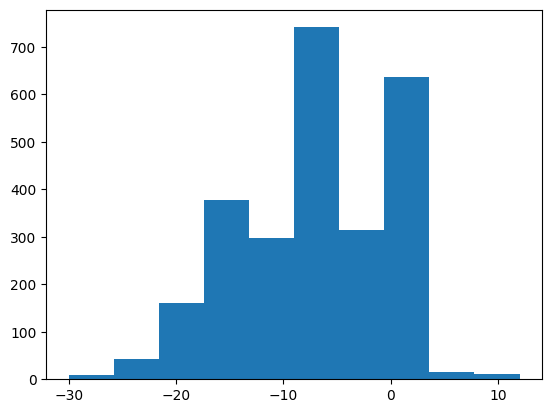

In [18]:
plt.hist(df_loop['cap_gap'])

In [19]:
d = df_loop[~df_loop["overloaded"]]
d = d.assign(pos = d["cap_gap"] > 0)

print("quota cap_gap>0 per L:\n", d.groupby("L")["pos"].mean().round(3))
print("quota cap_gap>0 per theta:\n", d.groupby("theta")["pos"].mean().round(3))
print("totale:", d["pos"].mean().round(4), "su", len(d), "casi")
print("gap positivi (in unità di L):\n",
      (d.loc[d.pos, "cap_gap"] / d.loc[d.pos, "L"]).value_counts().sort_index())

quota cap_gap>0 per L:
 L
2    0.011
3    0.008
4    0.008
5    0.011
6    0.019
7    0.008
8    0.024
Name: pos, dtype: float64
quota cap_gap>0 per theta:
 theta
0.2    0.000
0.3    0.000
0.4    0.012
0.5    0.039
Name: pos, dtype: float64
totale: 0.0127 su 2602 casi
gap positivi (in unità di L):
 1.0    31
2.0     2
Name: count, dtype: int64


In [15]:
df_loop.to_clipboard()

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def plot_loop_verdict(df, tol=1, title=None):
    ok = df.copy()                      # giorni sovraccarichi esclusi

    def cat(r):
        if not r["changed"]:                 return "unchanged"
        if r["advantage"] >  tol:            return "better than θ sweep"
        if r["advantage"] < -tol:            return "worse than θ sweep"
        return "no gain over θ sweep"        # within ±tol

    ok["cat"] = ok.apply(cat, axis=1)
    order = ["unchanged", "no gain over θ sweep", "better than θ sweep", "worse than θ sweep"]
    col = dict(zip(order, ["#d9d9d9", "#8ecae6", "#2a9d8f", "#e76f51"]))

    thetas = sorted(ok["theta"].unique())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10,4), gridspec_kw={"width_ratios": [1.15, 1]})

    for i, t in enumerate(thetas):
        g = ok[ok["theta"] == t]; left = 0.0
        for c in order:
            n = int((g["cat"] == c).sum()); w = n / len(g)
            if n:
                a1.barh(i, w, left=left, color=col[c], edgecolor="white", height=0.62, label=c)
                if w >= 0.05: a1.text(left + w / 2, i, f"{n}", ha="center", va="center", fontsize=9)
            left += w
    n_ov = ok[ok["overloaded"]].groupby("theta").size().reindex(thetas, fill_value=0)
    a1.set_yticks(range(len(thetas)))
    a1.set_yticklabels([f"θ = {t:g}\n{int((ok['theta'] == t).sum())} days" +
                        (f" ({int(n_ov[t])} overloaded)" if n_ov[t] else "") for t in thetas], fontsize=9)
    a1.invert_yaxis(); a1.set_xlim(0, 1); a1.set_xlabel("share of days (numbers = days)")
    a1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    h, l = a1.get_legend_handles_labels(); u = dict(zip(l, h))
    a1.legend([u[c] for c in order if c in u], [c for c in order if c in u], fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    a1.set_title(f"What the loop does to the schedule | {title}", fontsize=10.5)

    from matplotlib.lines import Line2D
    ch = ok[ok["changed"]].copy(); rng = np.random.default_rng(0)   # destra: guadagno sullo sweep
    ch["dcap"] = ch["cap_B"] - ch["cap_A"]
    shape = lambda d: "^" if d > 1e-9 else ("v" if d < -1e-9 else "o")
    ch["mk"] = ch["dcap"].map(shape)
    jit = {t: rng.uniform(-0.18, 0.18, int((ch["theta"] == t).sum())) for t in thetas}

    for i, t in enumerate(thetas):
        g = ch[ch["theta"] == t]
        if g.empty: continue
        x = i + jit[t]
        for mk in ("o", "^", "v"):
            m = (g["mk"] == mk).values
            if m.any():
                a2.scatter(x[m], g["advantage"].values[m], c=[col[c] for c in g["cat"].values[m]], marker=mk,
                           edgecolor="#444", linewidth=0.5, s=46 if mk != "o" else 34, zorder=3)
        a2.hlines(g["advantage"].median(), i - 0.3, i + 0.3, color="black", lw=1.6, zorder=4)
    a2.axhspan(-tol, tol, color="#cfcfcf", alpha=0.7, zorder=0, lw=0)
    a2.axhline(0, color="#666", lw=0.8, zorder=1)
    a2.text(0.995, 0.5, f"band = ±{tol:g} min: no difference", transform=a2.get_yaxis_transform(),
            ha="right", va="bottom", fontsize=7.5, color="#555")

    a2.set_xticks(range(len(thetas)))
    a2.set_xticklabels([f"θ = {t:g}\n{int((g_ := ch[ch['theta'] == t]).shape[0])} changed" for t in thetas], fontsize=9)
    a2.set_ylabel("mean wait saved vs best plain schedule (min)", fontsize=9)
    a2.set_title("Gain over a θ sweep at equal or lower capacity\n(black bar = median)", fontsize=10)
    hs = [Line2D([], [], marker="o", ls="", mfc="#bbb", mec="#444", ms=6, label="blocks moved, same capacity"),
          Line2D([], [], marker="^", ls="", mfc="#bbb", mec="#444", ms=7, label="capacity added (+1 block)")]
    if (ch["dcap"] < -1e-9).any():
        hs.append(Line2D([], [], marker="v", ls="", mfc="#bbb", mec="#444", ms=7, label="capacity reduced"))
    a2.legend(handles=hs, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False)

    for ax in (a1, a2):
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.tight_layout(); return fig

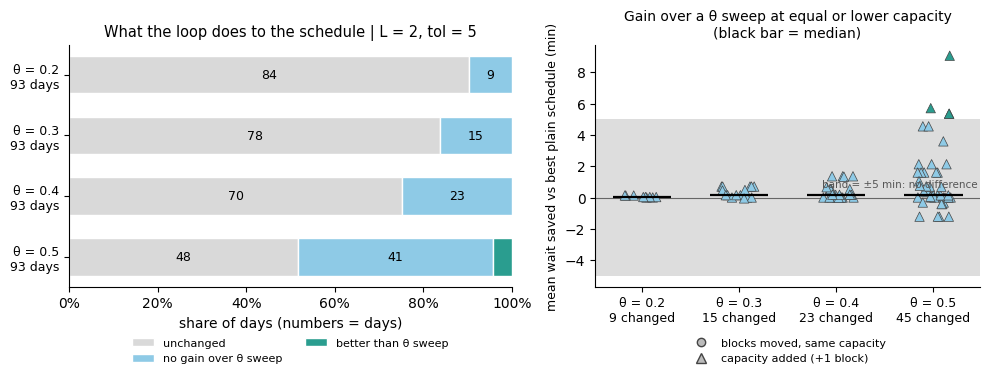

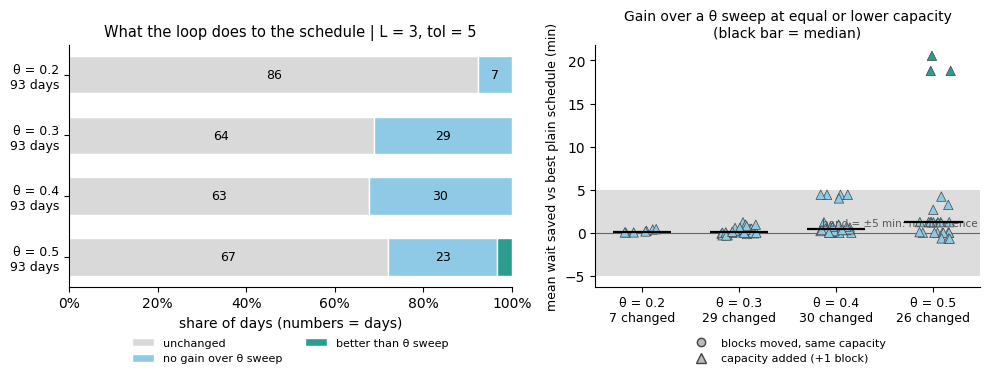

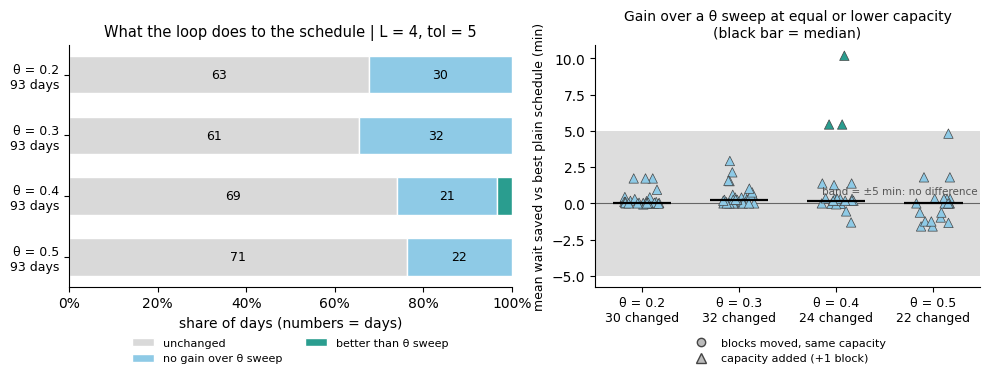

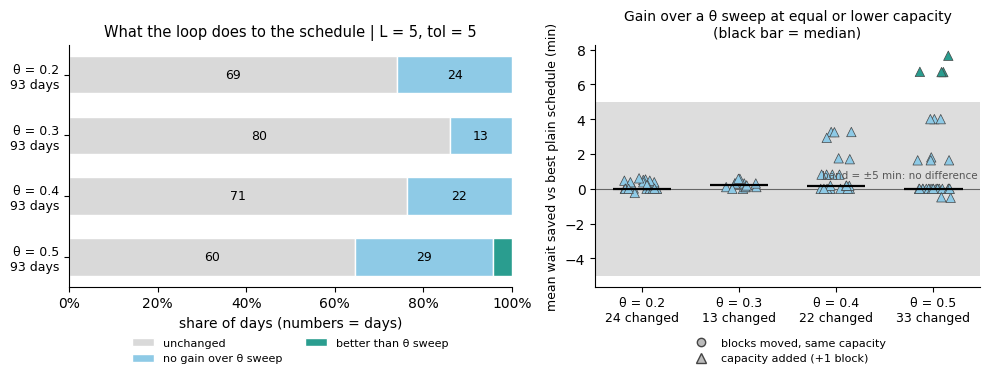

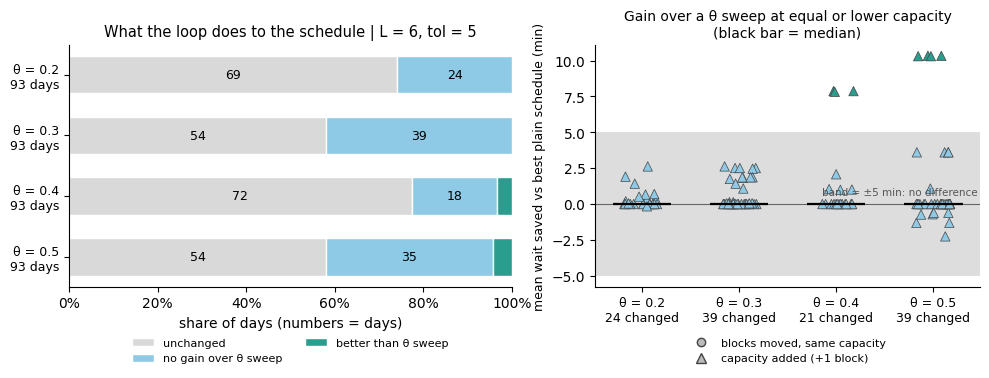

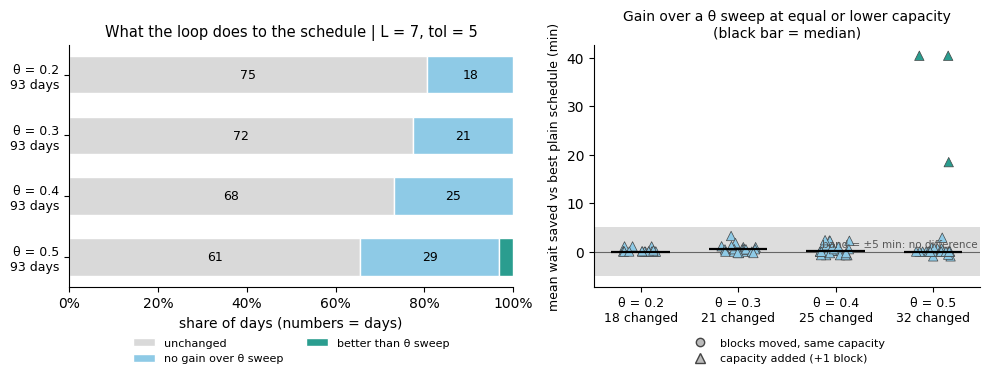

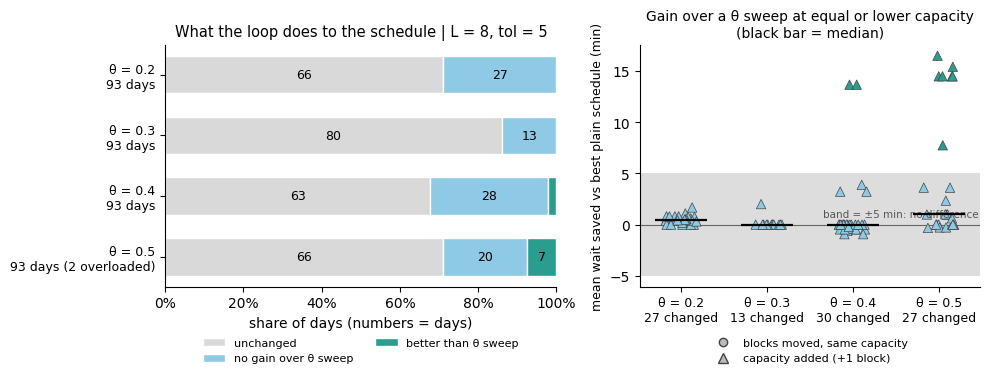

In [21]:
tol=5
for l in df_loop.L.unique():
    plot_loop_verdict(df_loop[df_loop.L == l], tol=tol, title=f"L = {l}, tol = {tol}")

In [35]:
ok = df_loop[~df_loop.overloaded]
for tol in (1, 5):
    t = ok.assign(beats=lambda x: x.changed & (x.advantage > tol),
                  worse=lambda x: x.changed & (x.advantage < -tol))
    print(f"\n=== tol = {tol} min ===")
    print(t.groupby(["L", "theta"])[["changed", "beats", "worse"]].sum().unstack("theta"))
    print(t.groupby("L")[["beats", "worse"]].agg(["sum", "mean"]).round(3))
    print("mediana advantage dei casi 'beats':", t[t.beats].groupby("L").advantage.median().round(1).to_dict())


=== tol = 1 min ===
      changed             beats             worse            
theta     0.2 0.3 0.4 0.5   0.2 0.3 0.4 0.5   0.2 0.3 0.4 0.5
L                                                            
4          32  33  23  18     0   5  11   1     0   0   1   2
8          26  15  31  26     8   1   4   8     0   0   0   4
10         10   6  26  21     2   5  17  13     0   0   1   5
   beats        worse       
     sum   mean   sum   mean
L                           
4     17  0.046     3  0.008
8     21  0.057     4  0.011
10    37  0.102     6  0.016
mediana advantage dei casi 'beats': {4: 2.8, 8: 3.2, 10: 4.2}

=== tol = 5 min ===
      changed             beats             worse            
theta     0.2 0.3 0.4 0.5   0.2 0.3 0.4 0.5   0.2 0.3 0.4 0.5
L                                                            
4          32  33  23  18     0   0   5   0     0   0   0   0
8          26  15  31  26     0   0   2   7     0   0   0   1
10         10   6  26  21     0   0  10 

#### Testing improve coverage